In [4]:
# ============================================================
# BLOCK 1 — LOAD, COMBINE AND INSPECT DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Load the three datasets
# ------------------------------------------------------------

train_df = pd.read_csv("data/train_timeseries.csv")
val_df   = pd.read_csv("data/validation_timeseries.csv")
test_df  = pd.read_csv("data/test_timeseries.csv")

soil_df = pd.read_csv("data/soil_data.csv")

print("Train shape :", train_df.shape)
print("Validation shape :", val_df.shape)
print("Test shape :", test_df.shape)
print("Soil shape :", soil_df.shape)


# ------------------------------------------------------------
# 2. Combine the meteorological datasets
# ------------------------------------------------------------

weather_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print("\nCombined weather data:")
print(weather_df.shape)


# ------------------------------------------------------------
# 3. Convert date
# ------------------------------------------------------------

weather_df["date"] = pd.to_datetime(
    weather_df["date"],
    errors="coerce"
)


# ------------------------------------------------------------
# 4. Convert drought score to integer
# ------------------------------------------------------------

weather_df["score"] = pd.to_numeric(
    weather_df["score"],
    errors="coerce"
)

weather_df["score"] = weather_df["score"].round().astype("Int64")


# ------------------------------------------------------------
# 5. Sort chronologically
# ------------------------------------------------------------

weather_df = weather_df.sort_values(
    ["fips", "date"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. Basic information
# ------------------------------------------------------------

print("\nColumns:")
print(weather_df.columns.tolist())

print("\nMissing values:")
print(weather_df.isna().sum())

print("\nDuplicate rows:")
print(weather_df.duplicated().sum())

print("\nDate range:")
print(weather_df["date"].min())
print(weather_df["date"].max())

print("\nNumber of counties:")
print(weather_df["fips"].nunique())

Train shape : (19300680, 21)
Validation shape : (2268840, 21)
Test shape : (2271948, 21)
Soil shape : (3109, 32)

Combined weather data:
(23841468, 21)

Columns:
['fips', 'date', 'PRECTOT', 'PS', 'QV2M', 'T2M', 'T2MDEW', 'T2MWET', 'T2M_MAX', 'T2M_MIN', 'T2M_RANGE', 'TS', 'WS10M', 'WS10M_MAX', 'WS10M_MIN', 'WS10M_RANGE', 'WS50M', 'WS50M_MAX', 'WS50M_MIN', 'WS50M_RANGE', 'score']

Missing values:
fips                  0
date                  0
PRECTOT               0
PS                    0
QV2M                  0
T2M                   0
T2MDEW                0
T2MWET                0
T2M_MAX               0
T2M_MIN               0
T2M_RANGE             0
TS                    0
WS10M                 0
WS10M_MAX             0
WS10M_MIN             0
WS10M_RANGE           0
WS50M                 0
WS50M_MAX             0
WS50M_MIN             0
WS50M_RANGE           0
score          20435100
dtype: int64

Duplicate rows:
0

Date range:
2000-01-01 00:00:00
2020-12-31 00:00:00

Number of co

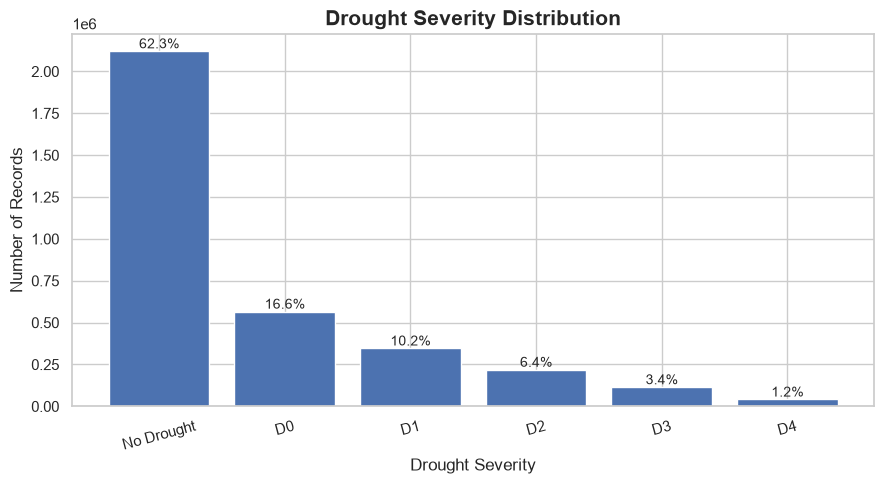

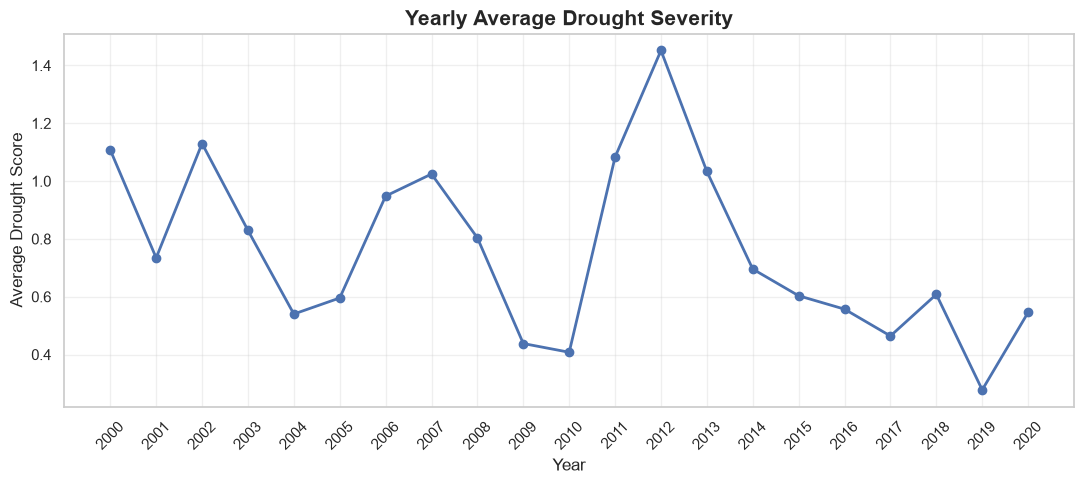

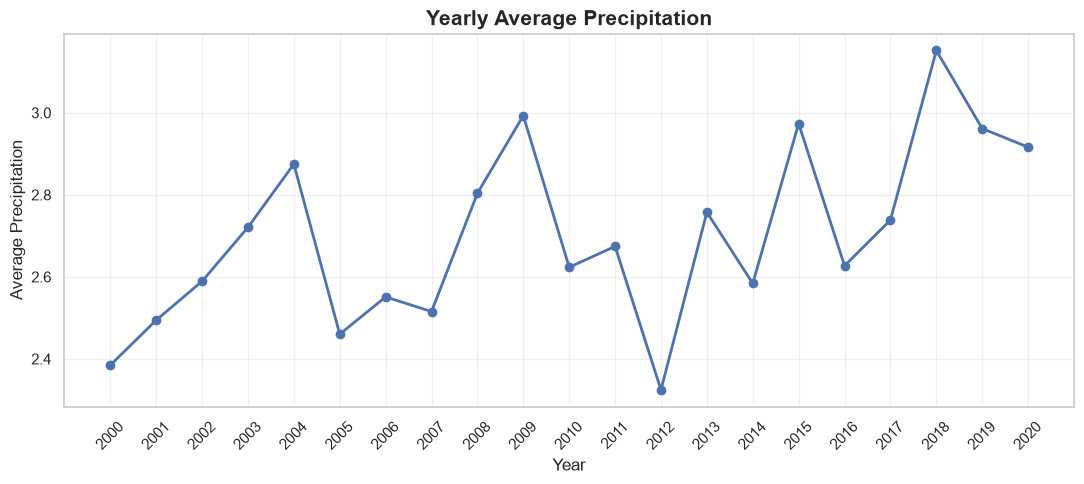

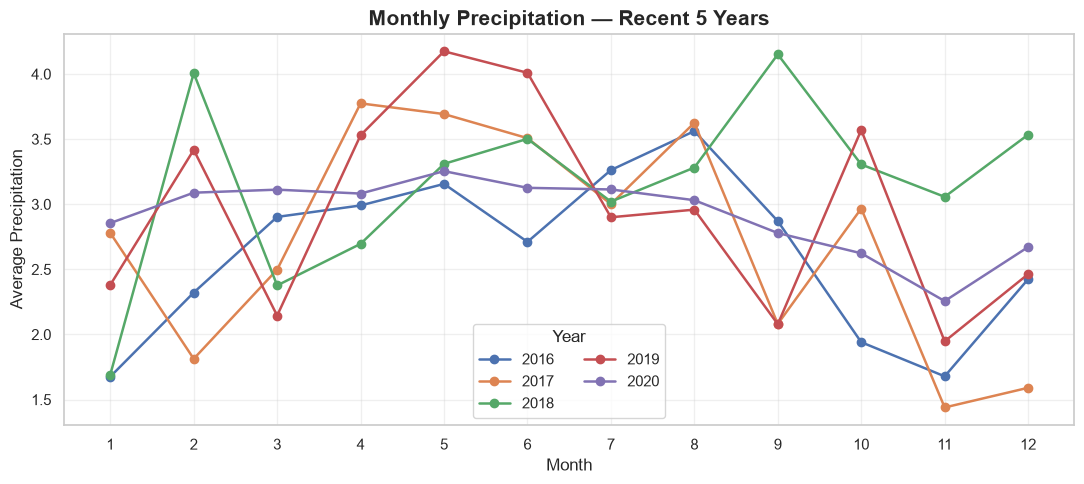

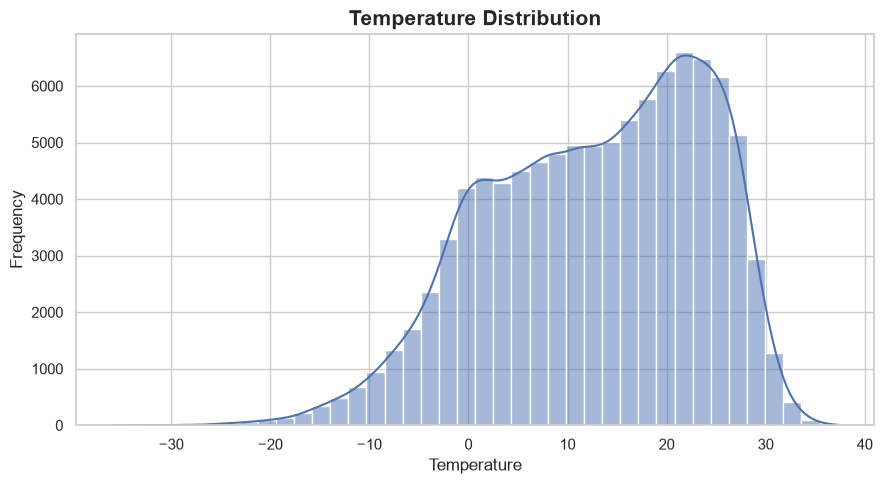

In [8]:
# ============================================================
# BLOCK 2 — CLEAN DATA VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")


# ============================================================
# 1. DROUGHT CLASS DISTRIBUTION
# ============================================================

class_counts = (
    weather_df["score"]
    .value_counts()
    .sort_index()
)

class_percent = (
    class_counts / class_counts.sum() * 100
)

class_labels = {
    0: "No Drought",
    1: "D0",
    2: "D1",
    3: "D2",
    4: "D3",
    5: "D4"
}

labels = [
    class_labels.get(int(x), str(x))
    for x in class_counts.index
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    class_counts.values
)

plt.title(
    "Drought Severity Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Drought Severity")
plt.ylabel("Number of Records")

# Add percentage above bars
for bar, pct in zip(bars, class_percent.values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


# ============================================================
# 2. YEARLY AVERAGE DROUGHT SEVERITY
# ============================================================

weather_df["year"] = weather_df["date"].dt.year

yearly_drought = (
    weather_df
    .groupby("year")["score"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 5))

plt.plot(
    yearly_drought["year"],
    yearly_drought["score"],
    marker="o",
    linewidth=2
)

plt.title(
    "Yearly Average Drought Severity",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Average Drought Score")

plt.xticks(
    yearly_drought["year"],
    rotation=45
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 3. YEARLY AVERAGE PRECIPITATION
# ============================================================

yearly_rain = (
    weather_df
    .groupby("year")["PRECTOT"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 5))

plt.plot(
    yearly_rain["year"],
    yearly_rain["PRECTOT"],
    marker="o",
    linewidth=2
)

plt.title(
    "Yearly Average Precipitation",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Average Precipitation")

plt.xticks(
    yearly_rain["year"],
    rotation=45
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 4. MONTHLY PRECIPITATION — SELECTED YEARS
# ============================================================

# Select only the last 5 years for a cleaner graph
max_year = weather_df["year"].max()

selected_years = list(
    range(max_year - 4, max_year + 1)
)

recent = weather_df[
    weather_df["year"].isin(selected_years)
].copy()

recent["month"] = recent["date"].dt.month

monthly_rain = (
    recent
    .groupby(["year", "month"])["PRECTOT"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 5))

for year in selected_years:

    temp = monthly_rain[
        monthly_rain["year"] == year
    ]

    plt.plot(
        temp["month"],
        temp["PRECTOT"],
        marker="o",
        linewidth=1.8,
        label=str(year)
    )

plt.title(
    "Monthly Precipitation — Recent 5 Years",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Average Precipitation")

plt.xticks(range(1, 13))

plt.legend(
    title="Year",
    ncol=2
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 5. TEMPERATURE DISTRIBUTION
# ============================================================

# Sample data only for visualization
temperature_sample = (
    weather_df["T2M"]
    .dropna()
    .sample(
        min(100000, weather_df["T2M"].notna().sum()),
        random_state=42
    )
)

plt.figure(figsize=(9, 5))

sns.histplot(
    temperature_sample,
    bins=40,
    kde=True
)

plt.title(
    "Temperature Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Temperature")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# BLOCK 3 — PREPROCESSING + TEMPORAL FEATURE ENGINEERING
# ============================================================

# ------------------------------------------------------------
# 1. Combine all three meteorological datasets
# ------------------------------------------------------------

weather_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print("Combined data:", weather_df.shape)


# ------------------------------------------------------------
# 2. Convert data types
# ------------------------------------------------------------

weather_df["date"] = pd.to_datetime(
    weather_df["date"],
    errors="coerce"
)

weather_df["fips"] = pd.to_numeric(
    weather_df["fips"],
    errors="coerce"
)

weather_df["score"] = pd.to_numeric(
    weather_df["score"],
    errors="coerce"
)

weather_df["score"] = (
    weather_df["score"]
    .round()
)


# ------------------------------------------------------------
# 3. Remove invalid rows
# ------------------------------------------------------------

weather_df = weather_df.dropna(
    subset=["fips", "date", "score"]
)


# ------------------------------------------------------------
# 4. Sort chronologically
# ------------------------------------------------------------

weather_df = weather_df.sort_values(
    ["fips", "date"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. Calendar features
# ------------------------------------------------------------

weather_df["month"] = (
    weather_df["date"].dt.month
)

weather_df["day_of_year"] = (
    weather_df["date"].dt.dayofyear
)


# ------------------------------------------------------------
# 6. Cyclical encoding
# ------------------------------------------------------------

weather_df["month_sin"] = np.sin(
    2 * np.pi *
    weather_df["month"] / 12
)

weather_df["month_cos"] = np.cos(
    2 * np.pi *
    weather_df["month"] / 12
)

weather_df["day_sin"] = np.sin(
    2 * np.pi *
    weather_df["day_of_year"] / 365.25
)

weather_df["day_cos"] = np.cos(
    2 * np.pi *
    weather_df["day_of_year"] / 365.25
)


# ------------------------------------------------------------
# 7. Rolling weather features
# ------------------------------------------------------------

weather_features = [
    "PRECTOT",
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "QV2M",
    "WS10M"
]

for col in weather_features:

    weather_df[f"{col}_mean_7d"] = (
        weather_df
        .groupby("fips")[col]
        .transform(
            lambda x:
            x.rolling(
                7,
                min_periods=1
            ).mean()
        )
    )

    weather_df[f"{col}_mean_30d"] = (
        weather_df
        .groupby("fips")[col]
        .transform(
            lambda x:
            x.rolling(
                30,
                min_periods=1
            ).mean()
        )
    )


# ------------------------------------------------------------
# 8. Merge soil data
# ------------------------------------------------------------

soil_df["fips"] = pd.to_numeric(
    soil_df["fips"],
    errors="coerce"
)

soil_df = soil_df.drop_duplicates(
    subset=["fips"]
)

processed_df = weather_df.merge(
    soil_df,
    on="fips",
    how="left",
    suffixes=("", "_soil")
)


# ------------------------------------------------------------
# 9. Save BASE processed dataset
# ------------------------------------------------------------

processed_df.to_csv(
    "processed_base.csv",
    index=False
)

print("=" * 70)
print("BASE PREPROCESSING COMPLETED")
print("=" * 70)

print("Shape:", processed_df.shape)

print("\nSaved as:")
print("processed_base.csv")

Combined data: (23841468, 21)
BASE PREPROCESSING COMPLETED
Shape: (3406368, 70)

Saved as:
processed_base.csv


In [18]:
# ============================================================
# BLOCK 4 — ORIGINAL VS PROCESSED DATA COMPARISON
# ============================================================

original_columns = set(
    weather_df.columns
)

processed_columns = set(
    processed_df.columns
)

new_columns = sorted(
    processed_columns - original_columns
)

comparison = pd.DataFrame({

    "Property": [
        "Rows",
        "Columns",
        "Unique Counties",
        "Missing Values",
        "Duplicate Rows",
        "Date Start",
        "Date End"
    ],

    "Original Dataset": [

        len(weather_df),

        len(weather_df.columns),

        weather_df["fips"].nunique(),

        weather_df.isna().sum().sum(),

        weather_df.duplicated().sum(),

        weather_df["date"].min(),

        weather_df["date"].max()
    ],

    "Processed Dataset": [

        len(processed_df),

        len(processed_df.columns),

        processed_df["fips"].nunique(),

        processed_df.isna().sum().sum(),

        processed_df.duplicated().sum(),

        processed_df["date"].min(),

        processed_df["date"].max()
    ]
})


print("=" * 80)
print("ORIGINAL DATASET VS PROCESSED DATASET")
print("=" * 80)

display(comparison)


# ============================================================
# NEW FEATURES CREATED
# ============================================================

print("\nNew features created during preprocessing:")

for col in new_columns:
    print("✓", col)

ORIGINAL DATASET VS PROCESSED DATASET


,Property,Original Dataset,Processed Dataset
0,Rows,3406368,3406368
1,Columns,39,70
2,Unique Counties,3108,3108
3,Missing Values,0,0
4,Duplicate Rows,0,0
5,Date Start,2000-01-04 00:00:00,2000-01-04 00:00:00
6,Date End,2020-12-29 00:00:00,2020-12-29 00:00:00



New features created during preprocessing:
✓ CULTIR_LAND
✓ CULTRF_LAND
✓ CULT_LAND
✓ FOR_LAND
✓ GRS_LAND
✓ NVG_LAND
✓ SQ1
✓ SQ2
✓ SQ3
✓ SQ4
✓ SQ5
✓ SQ6
✓ SQ7
✓ URB_LAND
✓ WAT_LAND
✓ aspectE
✓ aspectN
✓ aspectS
✓ aspectUnknown
✓ aspectW
✓ elevation
✓ lat
✓ lon
✓ slope1
✓ slope2
✓ slope3
✓ slope4
✓ slope5
✓ slope6
✓ slope7
✓ slope8


In [19]:
# ============================================================
# BLOCK 5 — ADD COUNTY LATITUDE / LONGITUDE
# ============================================================

# Load processed base data
processed_df = pd.read_csv(
    "processed_base.csv"
)

processed_df["date"] = pd.to_datetime(
    processed_df["date"]
)


# ------------------------------------------------------------
# CHECK FOR LAT/LON
# ------------------------------------------------------------

print(
    "Latitude exists:",
    "lat" in processed_df.columns
)

print(
    "Longitude exists:",
    "lon" in processed_df.columns
)

Latitude exists: True
Longitude exists: True


In [20]:
# ============================================================
# KEEP UNIQUE COUNTY COORDINATES
# ============================================================

county_locations = (
    processed_df[
        ["fips", "lat", "lon"]
    ]
    .drop_duplicates("fips")
    .dropna()
    .reset_index(drop=True)
)

print(
    "Counties with coordinates:",
    len(county_locations)
)

display(
    county_locations.head()
)

Counties with coordinates: 3108


,fips,lat,lon
0,1001,32.536382,-86.644490
1,1003,30.659218,-87.746067
2,1005,31.870670,-85.405456
3,1007,33.015893,-87.127148
4,1009,33.977448,-86.567246


In [21]:
# ============================================================
# BLOCK 6 — SPATIAL NEIGHBOUR / ADJACENCY MATRIX
# ============================================================

import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors


# ------------------------------------------------------------
# 1. County locations
# ------------------------------------------------------------

county_locations = (
    processed_df[
        ["fips", "lat", "lon"]
    ]
    .drop_duplicates("fips")
    .dropna()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Convert latitude / longitude to radians
# ------------------------------------------------------------

coordinates = np.radians(
    county_locations[
        ["lat", "lon"]
    ].values
)


# ------------------------------------------------------------
# 3. Number of neighbours
# ------------------------------------------------------------

K = 5


# ------------------------------------------------------------
# 4. Find nearest counties
# ------------------------------------------------------------

knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="haversine"
)

knn.fit(coordinates)


distances, indices = knn.kneighbors(
    coordinates
)


# ------------------------------------------------------------
# 5. Build adjacency matrix
# ------------------------------------------------------------

n_counties = len(county_locations)

adjacency_matrix = np.zeros(
    (n_counties, n_counties)
)


for i in range(n_counties):

    for j in range(1, K + 1):

        neighbour_index = indices[i, j]

        adjacency_matrix[
            i,
            neighbour_index
        ] = 1


# ------------------------------------------------------------
# 6. Display adjacency matrix
# ------------------------------------------------------------

print(
    "Adjacency matrix shape:",
    adjacency_matrix.shape
)

print(
    "Each county is connected to:",
    K,
    "nearest counties"
)

Adjacency matrix shape: (3108, 3108)
Each county is connected to: 5 nearest counties


In [22]:
# ============================================================
# BLOCK 6 — SPATIAL NEIGHBOUR / ADJACENCY MATRIX
# ============================================================

import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors


# ------------------------------------------------------------
# 1. County locations
# ------------------------------------------------------------

county_locations = (
    processed_df[
        ["fips", "lat", "lon"]
    ]
    .drop_duplicates("fips")
    .dropna()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Convert latitude / longitude to radians
# ------------------------------------------------------------

coordinates = np.radians(
    county_locations[
        ["lat", "lon"]
    ].values
)


# ------------------------------------------------------------
# 3. Number of neighbours
# ------------------------------------------------------------

K = 5


# ------------------------------------------------------------
# 4. Find nearest counties
# ------------------------------------------------------------

knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="haversine"
)

knn.fit(coordinates)


distances, indices = knn.kneighbors(
    coordinates
)


# ------------------------------------------------------------
# 5. Build adjacency matrix
# ------------------------------------------------------------

n_counties = len(county_locations)

adjacency_matrix = np.zeros(
    (n_counties, n_counties)
)


for i in range(n_counties):

    for j in range(1, K + 1):

        neighbour_index = indices[i, j]

        adjacency_matrix[
            i,
            neighbour_index
        ] = 1


# ------------------------------------------------------------
# 6. Display adjacency matrix
# ------------------------------------------------------------

print(
    "Adjacency matrix shape:",
    adjacency_matrix.shape
)

print(
    "Each county is connected to:",
    K,
    "nearest counties"
)

Adjacency matrix shape: (3108, 3108)
Each county is connected to: 5 nearest counties


In [23]:
# ============================================================
# BLOCK 6 — SPATIAL NEIGHBOUR / ADJACENCY MATRIX
# ============================================================

import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors


# ------------------------------------------------------------
# 1. County locations
# ------------------------------------------------------------

county_locations = (
    processed_df[
        ["fips", "lat", "lon"]
    ]
    .drop_duplicates("fips")
    .dropna()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Convert latitude / longitude to radians
# ------------------------------------------------------------

coordinates = np.radians(
    county_locations[
        ["lat", "lon"]
    ].values
)


# ------------------------------------------------------------
# 3. Number of neighbours
# ------------------------------------------------------------

K = 5


# ------------------------------------------------------------
# 4. Find nearest counties
# ------------------------------------------------------------

knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="haversine"
)

knn.fit(coordinates)


distances, indices = knn.kneighbors(
    coordinates
)


# ------------------------------------------------------------
# 5. Build adjacency matrix
# ------------------------------------------------------------

n_counties = len(county_locations)

adjacency_matrix = np.zeros(
    (n_counties, n_counties)
)


for i in range(n_counties):

    for j in range(1, K + 1):

        neighbour_index = indices[i, j]

        adjacency_matrix[
            i,
            neighbour_index
        ] = 1


# ------------------------------------------------------------
# 6. Display adjacency matrix
# ------------------------------------------------------------

print(
    "Adjacency matrix shape:",
    adjacency_matrix.shape
)

print(
    "Each county is connected to:",
    K,
    "nearest counties"
)

Adjacency matrix shape: (3108, 3108)
Each county is connected to: 5 nearest counties


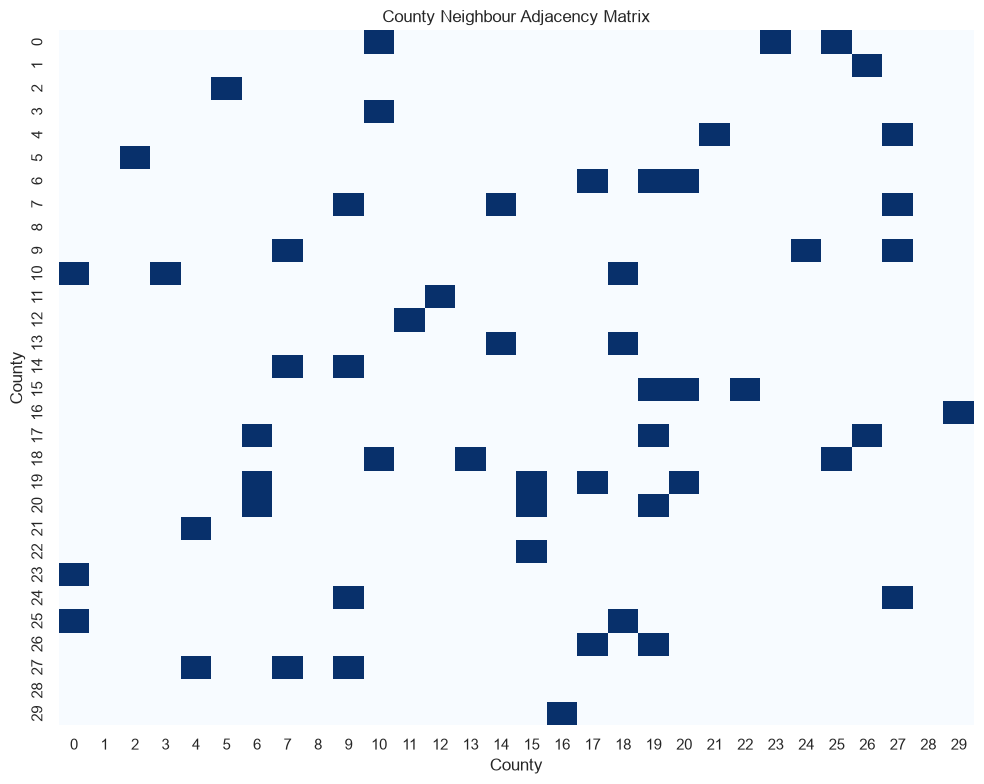

In [24]:
# ============================================================
# ADJACENCY MATRIX VISUALIZATION
# ============================================================

sample_size = min(
    30,
    n_counties
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    adjacency_matrix[
        :sample_size,
        :sample_size
    ],
    cmap="Blues",
    cbar=False
)

plt.title(
    "County Neighbour Adjacency Matrix"
)

plt.xlabel("County")
plt.ylabel("County")

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# FAST NEIGHBOUR SCORE CALCULATION
# ============================================================

neighbor_rows = []

for i, row in county_locations.iterrows():

    source_fips = row["fips"]

    neighbour_indices = indices[i, 1:]

    for j in neighbour_indices:

        neighbor_rows.append({

            "fips": source_fips,

            "neighbor_fips":
                county_locations.iloc[j]["fips"]
        })


neighbor_map = pd.DataFrame(
    neighbor_rows
)


# ------------------------------------------------------------
# Merge neighbour relationships with drought scores
# ------------------------------------------------------------

neighbor_scores = (
    neighbor_map
    .merge(
        processed_df[
            ["fips", "date", "score"]
        ],
        left_on="neighbor_fips",
        right_on="fips",
        how="left"
    )
)


# ------------------------------------------------------------
# Calculate average neighbour score
# ------------------------------------------------------------

neighbor_scores = (
    neighbor_scores
    .groupby(
        ["fips_x", "date"]
    )["score"]
    .mean()
    .reset_index()
)


neighbor_scores = neighbor_scores.rename(
    columns={
        "fips_x": "fips",
        "score": "neighbor_score"
    }
)


# ------------------------------------------------------------
# Add to main dataset
# ------------------------------------------------------------

processed_df = processed_df.merge(
    neighbor_scores,
    on=["fips", "date"],
    how="left"
)


print(
    processed_df[
        [
            "fips",
            "date",
            "score",
            "neighbor_score"
        ]
    ].head(20)
)

    fips       date  score  neighbor_score
0   1001 2000-01-04    1.0             1.0
1   1001 2000-01-11    2.0             2.0
2   1001 2000-01-18    2.0             2.0
3   1001 2000-01-25    2.0             2.0
4   1001 2000-02-01    1.0             1.0
5   1001 2000-02-08    1.0             1.0
6   1001 2000-02-15    1.0             1.0
7   1001 2000-02-22    1.0             1.0
8   1001 2000-02-29    1.0             1.0
9   1001 2000-03-07    1.0             1.0
10  1001 2000-03-14    1.0             1.4
11  1001 2000-03-21    2.0             1.4
12  1001 2000-03-28    1.0             1.4
13  1001 2000-04-04    1.0             1.2
14  1001 2000-04-11    1.0             1.0
15  1001 2000-04-18    1.0             1.4
16  1001 2000-04-25    1.0             1.2
17  1001 2000-05-02    1.0             1.4
18  1001 2000-05-09    2.0             2.4
19  1001 2000-05-16    2.0             2.6


In [36]:
# ============================================================
# FINAL ML DATASET
# ============================================================

feature_cols = [

    # Current drought
    "score",

    # Neighbour drought
    "neighbor_score",

    # Rainfall
    "PRECTOT_mean_7d",
    "PRECTOT_mean_30d",

    # Temperature
    "T2M_mean_30d",

    # Humidity
    "QV2M_mean_30d",

    # Wind
    "WS10M_mean_30d",

    # Seasonal
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",

    # Soil
    "CULT_LAND",
    "SQ1",
    "SQ2",
    "SQ3",
    "SQ4",
    "SQ5",
    "SQ6",
    "SQ7"
]


# Keep identification columns + ML features
final_columns = [
    "fips",
    "date"
] + feature_cols


processed_df = processed_df[
    final_columns
].copy()


print("=" * 70)
print("FINAL ML DATASET")
print("=" * 70)

print("Shape:", processed_df.shape)

print("\nFinal columns:")

for i, col in enumerate(
    processed_df.columns,
    1
):
    print(f"{i:02d}. {col}")

FINAL ML DATASET
Shape: (3406368, 21)

Final columns:
01. fips
02. date
03. score
04. neighbor_score
05. PRECTOT_mean_7d
06. PRECTOT_mean_30d
07. T2M_mean_30d
08. QV2M_mean_30d
09. WS10M_mean_30d
10. month_sin
11. month_cos
12. day_sin
13. day_cos
14. CULT_LAND
15. SQ1
16. SQ2
17. SQ3
18. SQ4
19. SQ5
20. SQ6
21. SQ7


In [37]:
# ============================================================
# SAVE FINAL SPATIAL DATASET
# ============================================================

processed_df.to_csv(
    "processed_spatial.csv",
    index=False
)

print("=" * 70)
print("FINAL SPATIAL DATASET SAVED")
print("=" * 70)

print(
    "File: processed_spatial.csv"
)

print(
    "Shape:",
    processed_df.shape
)

print(
    "Neighbour score missing:",
    processed_df["neighbor_score"]
    .isna()
    .sum()
)

FINAL SPATIAL DATASET SAVED
File: processed_spatial.csv
Shape: (3406368, 21)
Neighbour score missing: 0


In [6]:
# ============================================================
# BLOCK 3 — MERGE SOIL DATA + TEMPORAL FEATURES
# ============================================================

# ------------------------------------------------------------
# 1. Make FIPS type consistent
# ------------------------------------------------------------

weather_df["fips"] = pd.to_numeric(
    weather_df["fips"],
    errors="coerce"
)

soil_df["fips"] = pd.to_numeric(
    soil_df["fips"],
    errors="coerce"
)


# ------------------------------------------------------------
# 2. Remove duplicate soil records
# ------------------------------------------------------------

soil_df = soil_df.drop_duplicates(
    subset=["fips"]
)


# ------------------------------------------------------------
# 3. Merge weather + soil
# ------------------------------------------------------------

df = weather_df.merge(
    soil_df,
    on="fips",
    how="left",
    suffixes=("", "_soil")
)


print("After soil merge:")
print(df.shape)


# ------------------------------------------------------------
# 4. Calendar features
# ------------------------------------------------------------

df["month"] = df["date"].dt.month

df["day_of_year"] = (
    df["date"].dt.dayofyear
)


# ------------------------------------------------------------
# 5. Cyclical month encoding
# ------------------------------------------------------------

df["month_sin"] = np.sin(
    2 * np.pi * df["month"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * df["month"] / 12
)


# ------------------------------------------------------------
# 6. Cyclical day-of-year encoding
# ------------------------------------------------------------

df["day_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["day_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)


# ------------------------------------------------------------
# 7. Check new features
# ------------------------------------------------------------

calendar_features = [
    "month",
    "day_of_year",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos"
]

print("\nCalendar features:")
print(df[calendar_features].head())

After soil merge:
(23841468, 52)

Calendar features:
   month  day_of_year  month_sin  month_cos   day_sin   day_cos
0      1            1        0.5   0.866025  0.017202  0.999852
1      1            2        0.5   0.866025  0.034398  0.999408
2      1            3        0.5   0.866025  0.051584  0.998669
3      1            4        0.5   0.866025  0.068755  0.997634
4      1            5        0.5   0.866025  0.085906  0.996303



Rolling features:
   PRECTOT_mean_7d  PRECTOT_mean_30d  T2M_mean_30d  T2M_MAX_mean_30d  \
0         0.220000          0.220000        14.740         20.960000   
1         0.210000          0.210000        15.715         21.880000   
2         1.356667          1.356667        16.640         22.163333   
3         5.005000          5.005000        15.330         21.145000   
4         4.004000          4.004000        13.036         19.080000   

   T2M_MIN_mean_30d  QV2M_mean_30d  WS10M_mean_30d  
0           11.4600         9.6500        2.200000  
1           12.0350        10.0350        2.360000  
2           13.1300        10.6100        2.916667  
3           10.3875         9.5625        3.147500  
4            7.7780         8.2400        2.838000  


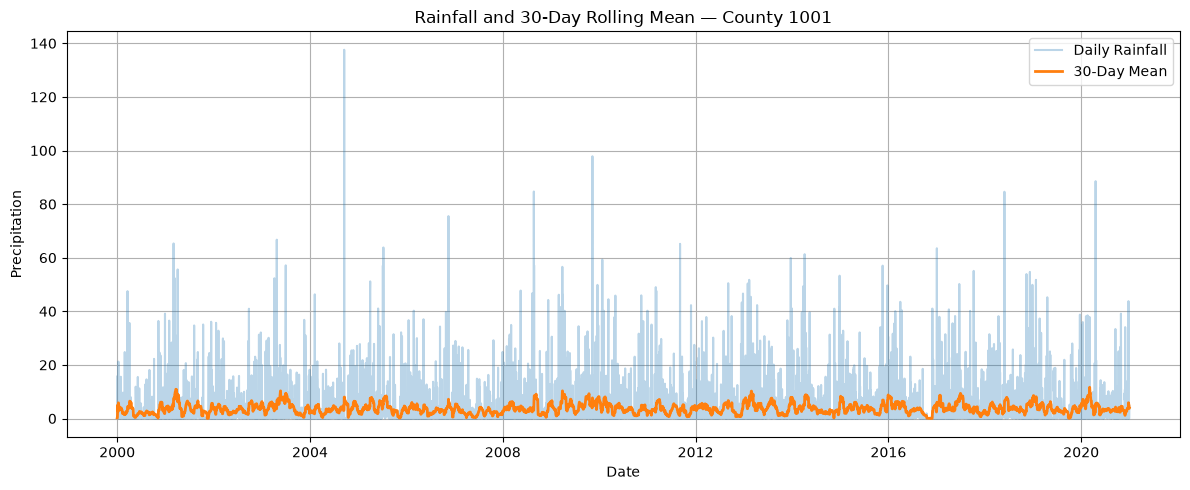

In [7]:
# ============================================================
# BLOCK 4 — WEATHER ROLLING FEATURES
# 7-DAY AND 30-DAY MEANS
# ============================================================

# ------------------------------------------------------------
# 1. Sort before rolling
# ------------------------------------------------------------

df = df.sort_values(
    ["fips", "date"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 2. Weather variables
# ------------------------------------------------------------

weather_features = [
    "PRECTOT",
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "QV2M",
    "WS10M"
]


# ------------------------------------------------------------
# 3. Create rolling features for each county
# ------------------------------------------------------------

for col in weather_features:

    # 7-day rolling mean
    df[f"{col}_mean_7d"] = (
        df
        .groupby("fips")[col]
        .transform(
            lambda x: x.rolling(
                window=7,
                min_periods=1
            ).mean()
        )
    )

    # 30-day rolling mean
    df[f"{col}_mean_30d"] = (
        df
        .groupby("fips")[col]
        .transform(
            lambda x: x.rolling(
                window=30,
                min_periods=1
            ).mean()
        )
    )


# ------------------------------------------------------------
# 4. Display created features
# ------------------------------------------------------------

rolling_features = [
    "PRECTOT_mean_7d",
    "PRECTOT_mean_30d",
    "T2M_mean_30d",
    "T2M_MAX_mean_30d",
    "T2M_MIN_mean_30d",
    "QV2M_mean_30d",
    "WS10M_mean_30d"
]

print("\nRolling features:")
print(df[rolling_features].head())


# ------------------------------------------------------------
# 5. Visualize rainfall rolling mean
# ------------------------------------------------------------

sample_fips = df["fips"].dropna().iloc[0]

sample = df[
    df["fips"] == sample_fips
].sort_values("date")


plt.figure(figsize=(12, 5))

plt.plot(
    sample["date"],
    sample["PRECTOT"],
    alpha=0.3,
    label="Daily Rainfall"
)

plt.plot(
    sample["date"],
    sample["PRECTOT_mean_30d"],
    linewidth=2,
    label="30-Day Mean"
)

plt.xlabel("Date")
plt.ylabel("Precipitation")
plt.title(
    f"Rainfall and 30-Day Rolling Mean — County {sample_fips}"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# FINAL COMPARISON
# ORIGINAL DATASET vs FINAL PROCESSED DATASET
# ============================================================

print("=" * 85)
print("ORIGINAL DATASET vs FINAL PROCESSED DATASET")
print("=" * 85)


# ------------------------------------------------------------
# 1. Basic information
# ------------------------------------------------------------

original_rows = weather_df.shape[0]
original_cols = weather_df.shape[1]

processed_rows = processed_df.shape[0]
processed_cols = processed_df.shape[1]


# ------------------------------------------------------------
# 2. Number of counties
# ------------------------------------------------------------

original_counties = weather_df["fips"].nunique()

processed_counties = processed_df["fips"].nunique()


# ------------------------------------------------------------
# 3. Date range
# ------------------------------------------------------------

original_start = weather_df["date"].min()
original_end = weather_df["date"].max()

processed_start = processed_df["date"].min()
processed_end = processed_df["date"].max()


# ------------------------------------------------------------
# 4. Missing values
# ------------------------------------------------------------

original_missing = weather_df.isna().sum().sum()

processed_missing = processed_df.isna().sum().sum()


# ------------------------------------------------------------
# 5. Duplicate records
# ------------------------------------------------------------

original_duplicates = weather_df.duplicated(
    subset=["fips", "date"]
).sum()

processed_duplicates = processed_df.duplicated(
    subset=["fips", "date"]
).sum()


# ------------------------------------------------------------
# 6. Create comparison table
# ------------------------------------------------------------

comparison = pd.DataFrame({

    "Property": [
        "Number of Rows",
        "Number of Columns",
        "Unique Counties",
        "Start Date",
        "End Date",
        "Missing Values",
        "Duplicate County-Date Records"
    ],

    "Original Dataset": [
        original_rows,
        original_cols,
        original_counties,
        original_start,
        original_end,
        original_missing,
        original_duplicates
    ],

    "Final Processed Dataset": [
        processed_rows,
        processed_cols,
        processed_counties,
        processed_start,
        processed_end,
        processed_missing,
        processed_duplicates
    ]
})


display(comparison)

ORIGINAL DATASET vs FINAL PROCESSED DATASET


,Property,Original Dataset,Final Processed Dataset
0,Number of Rows,3406368,3406368
1,Number of Columns,39,21
2,Unique Counties,3108,3108
3,Start Date,2000-01-04 00:00:00,2000-01-04 00:00:00
4,End Date,2020-12-29 00:00:00,2020-12-29 00:00:00
5,Missing Values,0,0
6,Duplicate County-Date Records,0,0
